In [1]:
"""
Project 1: 30-day hospital readmission risk, logistic regression vs LASSO
Dataset: UCI "Diabetes 130-US hospitals for years 1999-2008" (diabetic_data.csv)

Run:
    python readmission_glm_lasso.py --data data/diabetic_data.csv --out outputs
"""


import argparse
import os
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

NUMERIC = [
    "age_mid", "time_in_hospital", "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient", "number_emergency",
    "number_inpatient", "number_diagnoses",
]
CATEGORICAL = [
    "gender", "race", "admission_type", "discharge_group", "payer_group",
    "specialty_group", "diag_group", "A1Cresult", "change", "diabetesMed",
]

# discharge_disposition_id codes for death or hospice: these patients cannot be readmitted
EXPIRED_OR_HOSPICE = {11, 13, 14, 19, 20, 21}


def icd9_group(code):
    """Collapse the primary ICD-9 diagnosis code into broad groups."""
    if pd.isna(code) or code == "?":
        return "Unknown"
    code = str(code)
    if code.startswith(("E", "V")):
        return "Other"
    try:
        v = float(code)
    except ValueError:
        return "Other"
    if 390 <= v <= 459 or int(v) == 785:
        return "Circulatory"
    if 460 <= v <= 519 or int(v) == 786:
        return "Respiratory"
    if 520 <= v <= 579 or int(v) == 787:
        return "Digestive"
    if int(v) == 250:
        return "Diabetes"
    if 800 <= v <= 999:
        return "Injury"
    if 710 <= v <= 739:
        return "Musculoskeletal"
    if 580 <= v <= 629 or int(v) == 788:
        return "Genitourinary"
    if 140 <= v <= 239:
        return "Neoplasms"
    return "Other"


def age_to_mid(a):
    """'[70-80)' -> 75"""
    lo = int(str(a).strip("[)").split("-")[0])
    return lo + 5


def load_and_clean(path):
    df = pd.read_csv(path, na_values="?", low_memory=False)
    n0 = len(df)
    log = [("raw encounters", n0)]

    # remove patients who died or went to hospice
    df = df[~df["discharge_disposition_id"].isin(EXPIRED_OR_HOSPICE)]
    log.append(("after removing death/hospice discharges", len(df)))

    # keep only the first encounter per patient (repeated rows from the same
    # patient are not independent, which would make the confidence intervals too narrow)
    df = df.sort_values("encounter_id").drop_duplicates("patient_nbr", keep="first")
    log.append(("after keeping first encounter per patient", len(df)))

    df = df[df["gender"].isin(["Male", "Female"])]
    log.append(("after removing unknown gender", len(df)))

    # target: readmitted within 30 days
    df["readmit_30"] = (df["readmitted"] == "<30").astype(int)

    # features
    df["age_mid"] = df["age"].map(age_to_mid)
    df["race"] = df["race"].fillna("Unknown")
    df["A1Cresult"] = df["A1Cresult"].fillna("Not measured")
    df["diag_group"] = df["diag_1"].map(icd9_group)

    # admission type: 1=Emergency, 2=Urgent, 3=Elective, others are unknown
    df["admission_type"] = df["admission_type_id"].map(
        {1: "Emergency", 2: "Urgent", 3: "Elective"}
    ).fillna("Other")

    # discharge: 1 = home, 6 = home with home health
    df["discharge_group"] = np.where(
        df["discharge_disposition_id"] == 1, "Home",
        np.where(df["discharge_disposition_id"] == 6, "Home health", "Other facility"),
    )

    # payer: very relevant for RCM
    payer = df["payer_code"].fillna("Unknown")
    top_payers = payer.value_counts().head(6).index
    df["payer_group"] = payer.where(payer.isin(top_payers), "Other")

    # medical specialty: keep the 8 most common, the rest are Other
    spec = df["medical_specialty"].fillna("Unknown")
    top_spec = spec[spec != "Unknown"].value_counts().head(8).index
    df["specialty_group"] = np.where(
        spec == "Unknown", "Unknown", np.where(spec.isin(top_spec), spec, "Other")
    )

    keep = NUMERIC + CATEGORICAL + ["readmit_30"]
    return df[keep].reset_index(drop=True), log


def build_design(df):
    X = pd.get_dummies(df[NUMERIC + CATEGORICAL], columns=CATEGORICAL, drop_first=True)
    X = X.astype(float)
    y = df["readmit_30"].values
    return X, y


def main(args):
    os.makedirs(args.out, exist_ok=True)

    df, log = load_and_clean(args.data)
    with open(os.path.join(args.out, "cleaning_log.txt"), "w") as f:
        for name, n in log:
            line = f"{name}: {n}"
            print(line)
            f.write(line + "\n")
    print(f"Readmission rate (<30 days): {df['readmit_30'].mean():.3f}")

    X, y = build_design(df)
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )

    # standardise numeric columns using TRAIN statistics only (no leakage)
    mu = X_tr[NUMERIC].mean()
    sd = X_tr[NUMERIC].std().replace(0, 1)
    X_tr = X_tr.copy()
    X_te = X_te.copy()
    X_tr[NUMERIC] = (X_tr[NUMERIC] - mu) / sd
    X_te[NUMERIC] = (X_te[NUMERIC] - mu) / sd

    # ---------- Model 1: classical logistic regression (statsmodels) ----------
    glm = sm.Logit(y_tr, sm.add_constant(X_tr)).fit(disp=0, maxiter=200)
    with open(os.path.join(args.out, "glm_summary.txt"), "w") as f:
        f.write(str(glm.summary()))
    ci = glm.conf_int()
    or_table = pd.DataFrame({
        "odds_ratio": np.exp(glm.params),
        "ci_low": np.exp(ci[0]),
        "ci_high": np.exp(ci[1]),
        "p_value": glm.pvalues,
    }).drop(index="const")
    or_table.sort_values("p_value").to_csv(os.path.join(args.out, "glm_odds_ratios.csv"))

    p_glm = glm.predict(sm.add_constant(X_te, has_constant="add"))

    # ---------- Model 2: LASSO (L1) logistic regression, C chosen by 5-fold CV ----------
    lasso = LogisticRegressionCV(
        Cs=20, cv=5, penalty="l1", solver="saga", scoring="roc_auc",
        max_iter=5000, random_state=RANDOM_STATE, n_jobs=-1,
    ).fit(X_tr, y_tr)
    p_lasso = lasso.predict_proba(X_te)[:, 1]
    coefs = pd.Series(lasso.coef_[0], index=X_tr.columns)
    n_kept = int((coefs != 0).sum())
    coefs[coefs != 0].sort_values(key=np.abs, ascending=False).to_csv(
        os.path.join(args.out, "lasso_nonzero_coefficients.csv"), header=["coef"]
    )

    # ---------- Evaluation ----------
    results = pd.DataFrame({
        "model": ["Logistic (statsmodels)", "LASSO logistic"],
        "test_AUC": [roc_auc_score(y_te, p_glm), roc_auc_score(y_te, p_lasso)],
        "test_Brier": [brier_score_loss(y_te, p_glm), brier_score_loss(y_te, p_lasso)],
        "n_predictors": [X_tr.shape[1], n_kept],
    })
    results.to_csv(os.path.join(args.out, "model_comparison.csv"), index=False)
    print(results.to_string(index=False))
    print(f"Best C (LASSO): {lasso.C_[0]:.4f}; kept {n_kept} of {X_tr.shape[1]} predictors")

    # ROC
    plt.figure(figsize=(5.5, 5))
    for name, p in [("Logistic", p_glm), ("LASSO", p_lasso)]:
        fpr, tpr, _ = roc_curve(y_te, p)
        plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_te, p):.3f})")
    plt.plot([0, 1], [0, 1], "k--", lw=0.8)
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title("ROC on held-out test set")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(args.out, "roc.png"), dpi=150)
    plt.close()

    # Calibration
    plt.figure(figsize=(5.5, 5))
    for name, p in [("Logistic", p_glm), ("LASSO", p_lasso)]:
        frac, mean_p = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
        plt.plot(mean_p, frac, "o-", label=name)
    lim = max(0.01, float(np.max(p_glm)))
    plt.plot([0, lim], [0, lim], "k--", lw=0.8)
    plt.xlabel("Mean predicted probability")
    plt.ylabel("Observed readmission rate")
    plt.title("Calibration (10 quantile bins)")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(args.out, "calibration.png"), dpi=150)
    plt.close()

    # Forest plot of the 12 most significant odds ratios
    top = or_table.sort_values("p_value").head(12).iloc[::-1]
    plt.figure(figsize=(7, 5))
    ypos = np.arange(len(top))
    plt.errorbar(
        top["odds_ratio"], ypos,
        xerr=[top["odds_ratio"] - top["ci_low"], top["ci_high"] - top["odds_ratio"]],
        fmt="o", capsize=3,
    )
    plt.axvline(1, color="k", ls="--", lw=0.8)
    plt.yticks(ypos, top.index)
    plt.xlabel("Odds ratio (95% CI). Numeric variables are per 1 SD")
    plt.title("Strongest predictors of 30-day readmission")
    plt.tight_layout()
    plt.savefig(os.path.join(args.out, "forest_plot.png"), dpi=150)
    plt.close()

    # Logistic vs LASSO coefficients (shrinkage view)
    cmp_df = pd.DataFrame({"logistic": glm.params.drop("const"), "lasso": coefs})
    plt.figure(figsize=(5.5, 5))
    plt.scatter(cmp_df["logistic"], cmp_df["lasso"], s=14)
    m = float(cmp_df.abs().max().max())
    plt.plot([-m, m], [-m, m], "k--", lw=0.8)
    plt.xlabel("Logistic coefficient")
    plt.ylabel("LASSO coefficient")
    plt.title("LASSO shrinks and zeroes out coefficients")
    plt.tight_layout()
    plt.savefig(os.path.join(args.out, "coef_shrinkage.png"), dpi=150)
    plt.close()

    print(f"Done. Files saved in {args.out}/")


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default="C:/Users/gokul/Downloads/diabetic_data.csv")
    ap.add_argument("--out", default="outputs")
    # parse_known_args ignores extra arguments such as the "-f kernel.json" that Jupyter adds
    main(ap.parse_known_args()[0])

    

raw encounters: 101766
after removing death/hospice discharges: 99343
after keeping first encounter per patient: 69990
after removing unknown gender: 69987
Readmission rate (<30 days): 0.090


PermissionError: [Errno 13] Permission denied: 'outputs\\glm_odds_ratios.csv'

In [2]:
%pwd

'C:\\Users\\gokul'

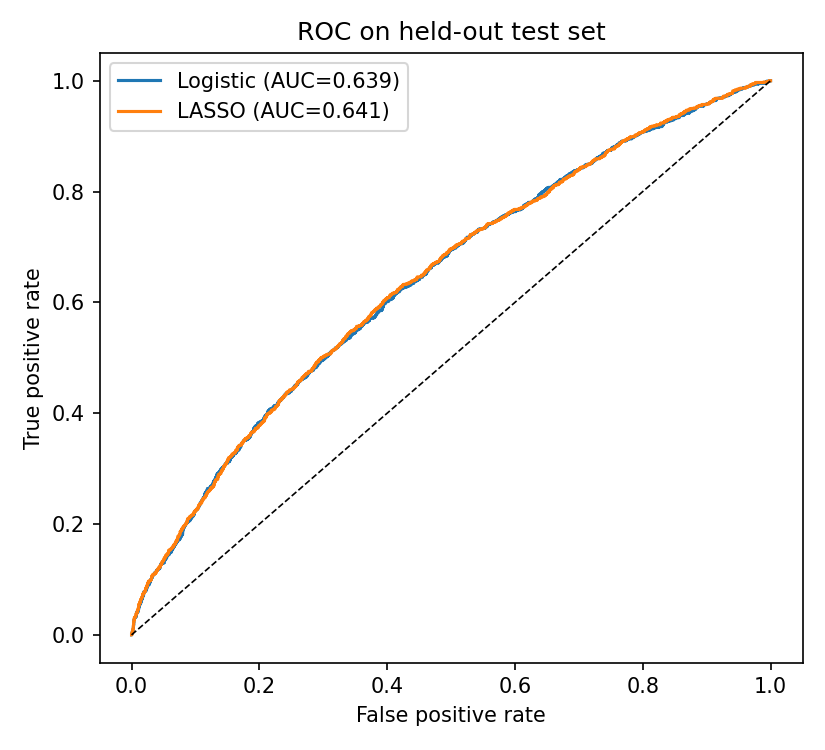

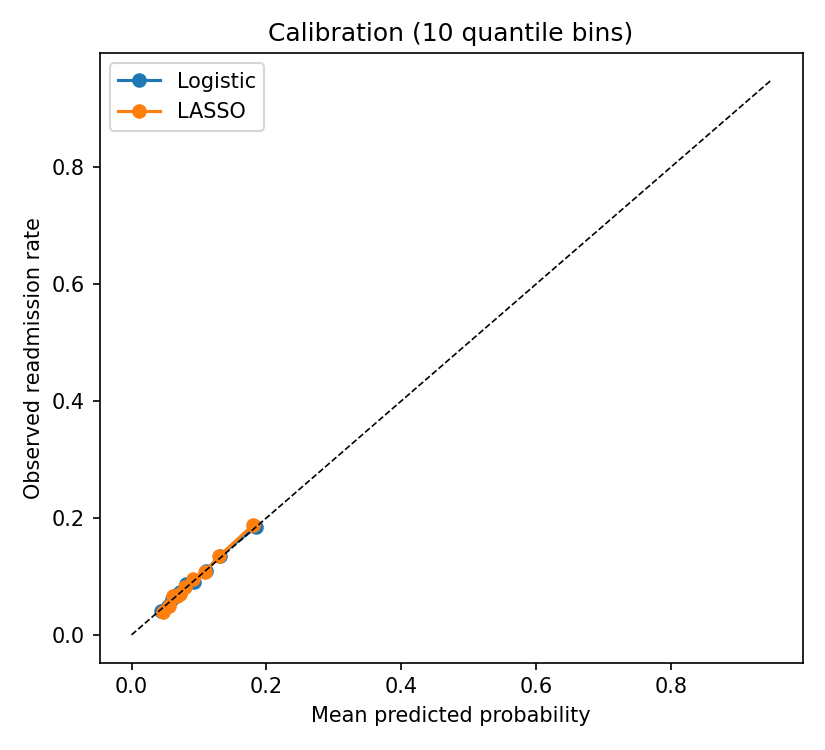

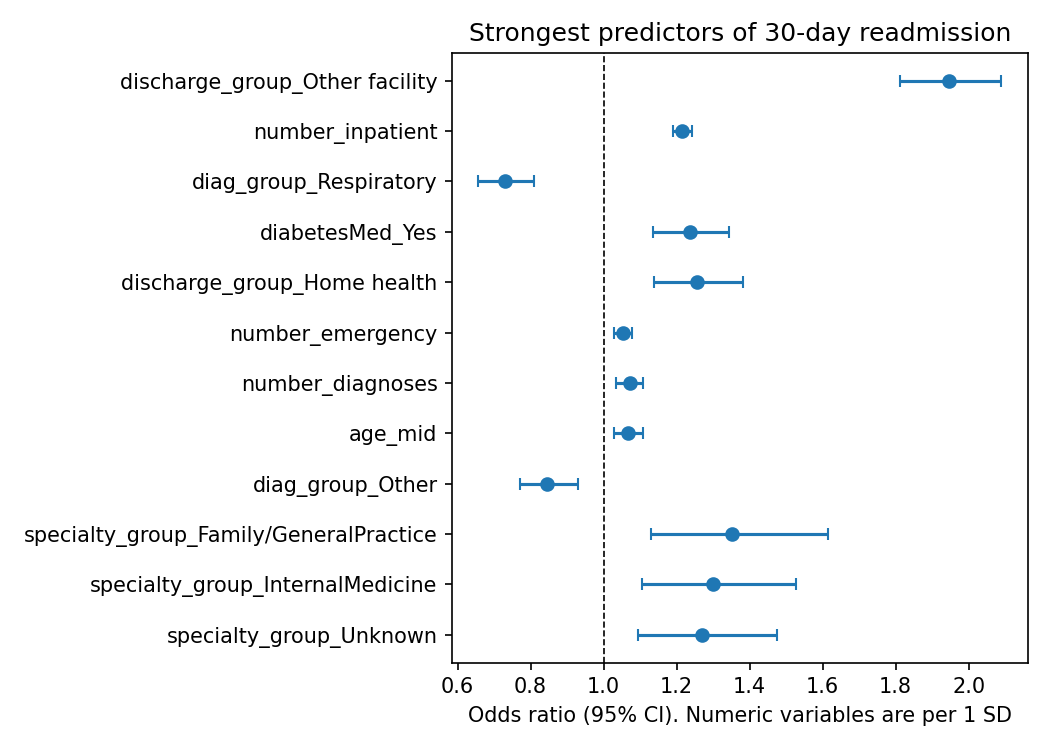

In [3]:
from IPython.display import Image, display
for f in ["roc.png", "calibration.png", "forest_plot.png"]:
    display(Image(filename=f"outputs/{f}"))